# ☀️ Solar Filament Segmentation — MAGFiLO 2026 v6.2 (Corrected Edge-Attention Multi-Task U-Net)

**v6.2 changes:** fixed file-level train/val split (prevents duplicate-annotation leakage across the split), guaranteed-non-empty instance extraction, and baseline-vs-tuned checkpoint comparison before final model selection.


## 1. Environment and hardware diagnostics

In [1]:
import os
import gc
import json
import math
import random
import time
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import cv2
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

from skimage.measure import label, regionprops
from skimage.segmentation import watershed
from scipy import ndimage as ndi

try:
    from pycocotools import mask as mask_utils
except ImportError as e:
    raise ImportError(
        "pycocotools is required for COCO RLE decoding/encoding. "
        "Install with: pip install pycocotools"
    ) from e

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print(f"VRAM: {props.total_memory / 1024**3:.2f} GB")

C:\Users\atiks\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA RTX A500 Laptop GPU
VRAM: 4.00 GB


## 2. Configuration

In [2]:
class Config:
    # Kaggle / local workspace layout
    BASE_DIR = Path("..") if Path("../MAGFiLO_1.0_Kaggle_2026").exists() else Path(".")
    TRAIN_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "train_images"
    TRAIN_JSON_PATH = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    TEST_IMG_DIR = BASE_DIR / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images"

    OUTPUT_DIR = Path("v6_outputs")
    BASELINE_MODEL_PATH = OUTPUT_DIR / "best_edgeatt_v6_50ep.pt"
    TUNED_MODEL_PATH = OUTPUT_DIR / "best_edgeatt_v6_tuned.pt"
    SUBMISSION_PATH = OUTPUT_DIR / "submission_v6_1.csv"
    HISTORY_PATH = OUTPUT_DIR / "v6_history.json"

    IMAGE_SIZE = 256
    BATCH_SIZE = 8
    NUM_EPOCHS = 50
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    VAL_SPLIT = 0.15
    NUM_WORKERS = 0

    BASE_CHANNELS = 32
    ATTN_HEADS = 4
    ATTN_EDGE_SCALE = 1.0

    # Multi-task loss weights
    MASK_LOSS_WEIGHT = 1.0
    SPINE_LOSS_WEIGHT = 0.5
    BBOX_LOSS_WEIGHT = 0.3

    # Post-processing
    PRED_THRESHOLD = 0.50
    SPINE_THRESHOLD = 0.45
    MIN_FILAMENT_AREA = 350
    MORPH_KERNEL_SIZE = 5
    MAX_FILAMENTS_PER_IMG = 30
    USE_SPINE_WATERSHED = True
    WATERSHED_MIN_DISTANCE = 8
    MATCH_IOU_THRESHOLD = 0.50

    DEVICE = DEVICE

config = Config()
config.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [config.TRAIN_IMG_DIR, config.TRAIN_JSON_PATH, config.TEST_IMG_DIR]:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

..\MAGFiLO_1.0_Kaggle_2026\train\train_images: OK
..\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json: OK
..\MAGFiLO_1.0_Kaggle_2026\test\test_images: OK


## 3. Load COCO annotations and build per-image records

In [3]:
print(f"Loading annotations from: {config.TRAIN_JSON_PATH}")
with open(config.TRAIN_JSON_PATH, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

category_names = {c["id"]: c.get("name", str(c["id"])) for c in coco_data.get("categories", [])}
image_meta = {img["id"]: img for img in coco_data["images"]}

# Preserve each annotation as a distinct instance.
annotations_by_image = {}
for ann in coco_data["annotations"]:
    annotations_by_image.setdefault(ann["image_id"], []).append(ann)

disk_files = {p.name for p in config.TRAIN_IMG_DIR.iterdir() if p.is_file()}

# Guard against accidental duplicate physical files being represented by multiple JSON image records.
json_filenames = [img["file_name"] for img in coco_data["images"]]
duplicate_filenames = sorted({f for f in json_filenames if json_filenames.count(f) > 1})
print(f"Duplicate JSON file names: {len(duplicate_filenames)}")
if duplicate_filenames:
    print("WARNING: duplicate physical file names detected. Check the annotation release before training.")

available_images = []
for image_id, img in image_meta.items():
    fname = img["file_name"]
    if fname not in disk_files:
        continue
    anns = annotations_by_image.get(image_id, [])
    instances = []
    for ann in anns:
        instances.append({
            "ann_id": ann["id"],
            "segmentation": ann.get("segmentation", []),
            "spine": ann.get("spine", []),
            "bbox": ann.get("bbox", []),
            "category_id": ann.get("category_id", 1),
            "area": ann.get("area", 0.0),
        })

    available_images.append({
        "image_id": image_id,
        "file_name": fname,
        "file_path": config.TRAIN_IMG_DIR / fname,
        "width": img.get("width", 2048),
        "height": img.get("height", 2048),
        "instances": instances,
        "filament_count": len(instances),
    })

print(f"JSON images: {len(coco_data['images'])}")
print(f"JSON annotations: {len(coco_data['annotations'])}")
print(f"Matched images on disk: {len(available_images)}")
print("Categories:", category_names)
print("Total parsed filament instances:", sum(x["filament_count"] for x in available_images))

Loading annotations from: ..\MAGFiLO_1.0_Kaggle_2026\train\MAGFiLO_1.0_Annotations_kaggle2026_train.json
Duplicate JSON file names: 296
JSON images: 1154
JSON annotations: 8199
Matched images on disk: 1154
Categories: {1: 'Left', 2: 'Right', 3: 'Unidentifiable', 4: 'Ambiguous'}
Total parsed filament instances: 8199


## 4. Rasterization helpers and visual audit

In [4]:
def polygon_to_points(poly):
    if not poly or len(poly) < 6:
        return []
    return [(float(poly[i]), float(poly[i+1])) for i in range(0, len(poly) - 1, 2)]


def segmentation_to_mask(segmentation, width, height):
    """Supports COCO polygon lists and RLE dictionaries."""
    mask = np.zeros((height, width), dtype=np.uint8)
    if isinstance(segmentation, dict):
        rle_obj = dict(segmentation)
        if isinstance(rle_obj.get("counts"), str):
            rle_obj["counts"] = rle_obj["counts"].encode("utf-8")
        decoded = mask_utils.decode(rle_obj)
        if decoded.ndim == 3:
            decoded = decoded[..., 0]
        return (decoded > 0).astype(np.uint8)
    if isinstance(segmentation, list):
        draw_img = Image.fromarray(mask)
        draw = ImageDraw.Draw(draw_img)
        for poly in segmentation:
            pts = polygon_to_points(poly)
            if len(pts) >= 3:
                draw.polygon(pts, fill=1)
        return np.asarray(draw_img, dtype=np.uint8)
    return mask


def rasterize_union_targets(sample, width, height, spine_width=3):
    mask = np.zeros((height, width), dtype=np.uint8)
    spine = Image.fromarray(np.zeros((height, width), dtype=np.uint8))
    bbox = Image.fromarray(np.zeros((height, width), dtype=np.uint8))
    spine_draw = ImageDraw.Draw(spine)
    bbox_draw = ImageDraw.Draw(bbox)

    for inst in sample["instances"]:
        mask |= segmentation_to_mask(inst["segmentation"], width, height)

        raw_spine = inst.get("spine") or []
        if len(raw_spine) >= 4:
            pts = [(float(raw_spine[i]), float(raw_spine[i+1])) for i in range(0, len(raw_spine) - 1, 2)]
            if len(pts) >= 2:
                spine_draw.line(pts, fill=1, width=spine_width)

        bbox_vals = inst.get("bbox") or []
        if len(bbox_vals) == 4:
            x, y, w, h = map(float, bbox_vals)
            bbox_draw.rectangle([x, y, x + w, y + h], fill=1)

    return mask, np.asarray(spine, dtype=np.uint8), np.asarray(bbox, dtype=np.uint8)

# Visual audit: choose images with multiple filaments when available.
visual_samples = [s for s in available_images if s["filament_count"] >= 3][:3]
if visual_samples:
    fig, axes = plt.subplots(len(visual_samples), 4, figsize=(20, 5 * len(visual_samples)), squeeze=False)
    for row, sample in enumerate(visual_samples):
        img = np.asarray(Image.open(sample["file_path"]).convert("L"))
        mask, spine, bbox = rasterize_union_targets(sample, sample["width"], sample["height"])
        ax = axes[row]
        ax[0].imshow(img, cmap="gray"); ax[0].set_title(sample["file_name"]); ax[0].axis("off")
        ax[1].imshow(mask, cmap="gray"); ax[1].set_title(f"Union mask ({sample['filament_count']} filaments)"); ax[1].axis("off")
        ax[2].imshow(spine, cmap="gray"); ax[2].set_title("Union spine"); ax[2].axis("off")
        ax[3].imshow(img, cmap="gray")
        for inst in sample["instances"]:
            if len(inst.get("bbox", [])) == 4:
                x, y, w, h = inst["bbox"]
                ax[3].add_patch(patches.Rectangle((x, y), w, h, fill=False, linewidth=1.5))
        ax[3].set_title("Bounding boxes"); ax[3].axis("off")
    plt.tight_layout()
    plt.show()

<Figure size 2000x1500 with 12 Axes>

## 5. Dataset with synchronized augmentation

In [5]:
class FilamentDataset(Dataset):
    def __init__(self, samples, image_size=256, is_train=True):
        self.samples = samples
        self.image_size = image_size
        self.is_train = is_train

    def __len__(self):
        return len(self.samples)

    @staticmethod
    def _make_targets(sample):
        w, h = sample["width"], sample["height"]
        return rasterize_union_targets(sample, w, h, spine_width=3)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        img = Image.open(sample["file_path"]).convert("L")
        mask_np, spine_np, bbox_np = self._make_targets(sample)

        img = img.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        mask = Image.fromarray(mask_np).resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
        spine = Image.fromarray(spine_np).resize((self.image_size, self.image_size), Image.Resampling.NEAREST)
        bbox = Image.fromarray(bbox_np).resize((self.image_size, self.image_size), Image.Resampling.NEAREST)

        if self.is_train:
            if random.random() < 0.5:
                img, mask, spine, bbox = map(TF.hflip, (img, mask, spine, bbox))
            if random.random() < 0.5:
                img, mask, spine, bbox = map(TF.vflip, (img, mask, spine, bbox))
            if random.random() < 0.5:
                angle = random.choice([90, 180, 270])
                img = TF.rotate(img, angle, interpolation=TF.InterpolationMode.BILINEAR)
                mask = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)
                spine = TF.rotate(spine, angle, interpolation=TF.InterpolationMode.NEAREST)
                bbox = TF.rotate(bbox, angle, interpolation=TF.InterpolationMode.NEAREST)

        image_t = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).unsqueeze(0)
        mask_t = torch.from_numpy(np.asarray(mask, dtype=np.float32)).unsqueeze(0)
        spine_t = torch.from_numpy(np.asarray(spine, dtype=np.float32)).unsqueeze(0)
        bbox_t = torch.from_numpy(np.asarray(bbox, dtype=np.float32)).unsqueeze(0)

        return image_t, mask_t, spine_t, bbox_t, sample["image_id"]

# File-level split (FIXED): group every image_id record by its underlying
# physical file_name first, so that if the same GONG observation was
# annotated more than once (see "Duplicate JSON file names" check above),
# all of its copies land on the SAME side of the split -- never split
# across train and val. Splitting by image_id directly (the old approach)
# could put one annotator's copy of an image in train and a second
# annotator's copy of the SAME image in val, which is leakage.
from collections import defaultdict

images_by_file = defaultdict(list)
for rec in available_images:
    images_by_file[rec["file_name"]].append(rec)

unique_files = sorted(images_by_file.keys())
print(f"Unique physical files: {len(unique_files)} (vs {len(available_images)} JSON image records)")

rng = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(unique_files), generator=rng).tolist()
val_file_count = max(1, int(round(len(unique_files) * config.VAL_SPLIT)))
val_files = {unique_files[i] for i in perm[:val_file_count]}
train_files = {unique_files[i] for i in perm[val_file_count:]}

train_samples = [rec for fname in train_files for rec in images_by_file[fname]]
val_samples = [rec for fname in val_files for rec in images_by_file[fname]]

train_dataset = FilamentDataset(train_samples, config.IMAGE_SIZE, True)
val_dataset = FilamentDataset(val_samples, config.IMAGE_SIZE, False)

train_loader = DataLoader(
    train_dataset, batch_size=config.BATCH_SIZE, shuffle=True,
    num_workers=config.NUM_WORKERS, pin_memory=(config.DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=config.BATCH_SIZE, shuffle=False,
    num_workers=config.NUM_WORKERS, pin_memory=(config.DEVICE.type == "cuda")
)

print(f"Training image_id records: {len(train_samples)} (from {len(train_files)} unique files)")
print(f"Validation image_id records: {len(val_samples)} (from {len(val_files)} unique files)")


Unique physical files: 707 (vs 1154 JSON image records)
Training image_id records: 985 (from 601 unique files)
Validation image_id records: 169 (from 106 unique files)


## 6. Correct Edge-Guided Attention U-Net

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class EdgeGuidedMHSA(nn.Module):
    """Edge-guided self-attention at the bottleneck.

    A learnable depthwise + pointwise edge extractor produces an edge feature.
    Edge features modify Q and K, while V remains the content feature. This keeps
    the attention map biased toward useful boundaries/fine structures without
    directly replacing the information being aggregated.
    """
    def __init__(self, channels, num_heads=4, edge_scale=1.0):
        super().__init__()
        if channels % num_heads != 0:
            raise ValueError("channels must be divisible by num_heads")
        self.channels = channels
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        self.edge_scale = edge_scale

        self.edge_conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.GELU(),
            nn.Conv2d(channels, channels, 1, bias=False),
        )
        self.q_proj = nn.Linear(channels, channels)
        self.k_proj = nn.Linear(channels, channels)
        self.v_proj = nn.Linear(channels, channels)
        self.out_proj = nn.Linear(channels, channels)
        self.norm = nn.LayerNorm(channels)

    def _split(self, t, b):
        return t.view(b, -1, self.num_heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        b, c, h, w = x.shape
        content = x.flatten(2).transpose(1, 2)  # B, N, C
        edge = self.edge_conv(x).flatten(2).transpose(1, 2)

        q = self._split(self.q_proj(self.norm(content + self.edge_scale * edge)), b)
        k = self._split(self.k_proj(self.norm(content + self.edge_scale * edge)), b)
        v = self._split(self.v_proj(self.norm(content)), b)

        attn = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attn = torch.softmax(attn, dim=-1)
        out = torch.matmul(attn, v)
        out = out.transpose(1, 2).reshape(b, h * w, c)
        out = self.out_proj(out)
        out = out + content
        return out.transpose(1, 2).reshape(b, c, h, w)


class EdgeAttFilamentUNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=32, attn_heads=4, edge_scale=1.0):
        super().__init__()
        bc = base_channels
        self.enc1 = ConvBlock(in_channels, bc)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(bc, bc * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ConvBlock(bc * 2, bc * 4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ConvBlock(bc * 4, bc * 8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(bc * 8, bc * 16)
        self.edge_attn = EdgeGuidedMHSA(bc * 16, num_heads=attn_heads, edge_scale=edge_scale)

        self.up4 = nn.ConvTranspose2d(bc * 16, bc * 8, 2, 2)
        self.dec4 = ConvBlock(bc * 16, bc * 8)
        self.up3 = nn.ConvTranspose2d(bc * 8, bc * 4, 2, 2)
        self.dec3 = ConvBlock(bc * 8, bc * 4)
        self.up2 = nn.ConvTranspose2d(bc * 4, bc * 2, 2, 2)
        self.dec2 = ConvBlock(bc * 4, bc * 2)
        self.up1 = nn.ConvTranspose2d(bc * 2, bc, 2, 2)
        self.dec1 = ConvBlock(bc * 2, bc)

        self.head_mask = nn.Conv2d(bc, 1, 1)
        self.head_spine = nn.Conv2d(bc, 1, 1)
        self.head_bbox = nn.Conv2d(bc, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b = self.bottleneck(self.pool4(e4))
        b = self.edge_attn(b)

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return {
            "mask": self.head_mask(d1),
            "spine": self.head_spine(d1),
            "bbox": self.head_bbox(d1),
        }


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_probe = EdgeAttFilamentUNet(
    in_channels=1,
    base_channels=config.BASE_CHANNELS,
    attn_heads=config.ATTN_HEADS,
    edge_scale=config.ATTN_EDGE_SCALE,
).to(config.DEVICE)
print(f"Trainable parameters: {count_parameters(model_probe):,}")
del model_probe

Trainable parameters: 9,080,931


## 7. Losses and pixel metrics

In [7]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        intersection = (probs * targets).sum(dims)
        denom = probs.sum(dims) + targets.sum(dims)
        dice = (2 * intersection + self.smooth) / (denom + self.smooth)
        return 1 - dice.mean()


def dice_score_from_logits(logits, targets, threshold=0.5):
    with torch.no_grad():
        pred = (torch.sigmoid(logits) >= threshold).float()
        dims = (1, 2, 3)
        inter = (pred * targets).sum(dims)
        denom = pred.sum(dims) + targets.sum(dims)
        score = torch.where(denom > 0, 2 * inter / (denom + 1e-8), torch.ones_like(denom))
        return score.mean().item()


def iou_score_from_logits(logits, targets, threshold=0.5):
    with torch.no_grad():
        pred = (torch.sigmoid(logits) >= threshold).float()
        dims = (1, 2, 3)
        inter = (pred * targets).sum(dims)
        union = pred.sum(dims) + targets.sum(dims) - inter
        score = torch.where(union > 0, inter / (union + 1e-8), torch.ones_like(union))
        return score.mean().item()


def multitask_loss(outputs, masks, spines, bboxes):
    bce = nn.BCEWithLogitsLoss()
    dice = DiceLoss()
    loss_mask = bce(outputs["mask"], masks) + dice(outputs["mask"], masks)
    loss_spine = bce(outputs["spine"], spines) + dice(outputs["spine"], spines)
    loss_bbox = bce(outputs["bbox"], bboxes) + dice(outputs["bbox"], bboxes)
    total = (
        config.MASK_LOSS_WEIGHT * loss_mask
        + config.SPINE_LOSS_WEIGHT * loss_spine
        + config.BBOX_LOSS_WEIGHT * loss_bbox
    )
    return total, {"mask": loss_mask, "spine": loss_spine, "bbox": loss_bbox}

print("Loss and metric helpers ready.")

Loss and metric helpers ready.


## 8. Training utilities

In [8]:
def autocast_context(device):
    if device.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return torch.autocast(device_type="cpu", dtype=torch.bfloat16, enabled=False)


def make_scaler(device):
    return torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


def save_checkpoint(path, model, config_dict, epoch, metrics, optimizer=None):
    payload = {
        "epoch": int(epoch),
        "model_state": model.state_dict(),
        "model_config": config_dict,
        "metrics": metrics,
    }
    if optimizer is not None:
        payload["optimizer_state"] = optimizer.state_dict()
    torch.save(payload, path)


def load_checkpoint(path, device):
    payload = torch.load(path, map_location=device)
    model_cfg = payload.get("model_config", {})
    model = EdgeAttFilamentUNet(
        in_channels=model_cfg.get("in_channels", 1),
        base_channels=model_cfg.get("base_channels", config.BASE_CHANNELS),
        attn_heads=model_cfg.get("attn_heads", config.ATTN_HEADS),
        edge_scale=model_cfg.get("edge_scale", config.ATTN_EDGE_SCALE),
    ).to(device)
    model.load_state_dict(payload["model_state"])
    return model, payload


def run_epoch(model, loader, optimizer=None, scaler=None, device=None):
    is_train = optimizer is not None
    model.train(is_train)

    totals = {"loss": 0.0, "mask_dice": 0.0, "mask_iou": 0.0, "spine_dice": 0.0, "bbox_dice": 0.0}
    count = 0

    for batch in loader:
        imgs, masks, spines, bboxes, _ = batch
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        spines = spines.to(device, non_blocking=True)
        bboxes = bboxes.to(device, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        grad_ctx = torch.enable_grad() if is_train else torch.no_grad()
        with grad_ctx:
            with autocast_context(device):
                outputs = model(imgs)
                loss, loss_parts = multitask_loss(outputs, masks, spines, bboxes)

            if is_train:
                if scaler is not None and device.type == "cuda":
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        bs = imgs.shape[0]
        totals["loss"] += loss.item() * bs
        totals["mask_dice"] += dice_score_from_logits(outputs["mask"], masks) * bs
        totals["mask_iou"] += iou_score_from_logits(outputs["mask"], masks) * bs
        totals["spine_dice"] += dice_score_from_logits(outputs["spine"], spines) * bs
        totals["bbox_dice"] += dice_score_from_logits(outputs["bbox"], bboxes) * bs
        count += bs

    return {k: v / max(count, 1) for k, v in totals.items()}

## 9. 50-epoch corrected baseline

In [9]:
model = EdgeAttFilamentUNet(
    in_channels=1,
    base_channels=config.BASE_CHANNELS,
    attn_heads=config.ATTN_HEADS,
    edge_scale=config.ATTN_EDGE_SCALE,
).to(config.DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=config.LEARNING_RATE, weight_decay=config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=config.NUM_EPOCHS, eta_min=1e-6
)
scaler = make_scaler(config.DEVICE)

history_v6 = []
best_val_dice = -1.0

print(f"Starting corrected v6.1 baseline: {count_parameters(model):,} parameters")
start_time = time.time()

for epoch in range(1, config.NUM_EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, optimizer, scaler, config.DEVICE)
    with torch.no_grad():
        val_metrics = run_epoch(model, val_loader, None, None, config.DEVICE)
    scheduler.step()
    lr_now = scheduler.get_last_lr()[0]

    record = {
        "epoch": epoch,
        "lr": lr_now,
        "train": train_metrics,
        "val": val_metrics,
    }
    history_v6.append(record)

    save_msg = ""
    if val_metrics["mask_dice"] > best_val_dice:
        best_val_dice = val_metrics["mask_dice"]
        save_checkpoint(
            config.BASELINE_MODEL_PATH,
            model,
            {
                "in_channels": 1,
                "base_channels": config.BASE_CHANNELS,
                "attn_heads": config.ATTN_HEADS,
                "edge_scale": config.ATTN_EDGE_SCALE,
            },
            epoch,
            val_metrics,
        )
        save_msg = f" | saved: {config.BASELINE_MODEL_PATH}"

    print(
        f"Epoch {epoch:02d}/{config.NUM_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val Dice {val_metrics['mask_dice']:.4f} | "
        f"val IoU {val_metrics['mask_iou']:.4f} | "
        f"spine Dice {val_metrics['spine_dice']:.4f} | "
        f"bbox Dice {val_metrics['bbox_dice']:.4f} | "
        f"lr {lr_now:.2e}{save_msg}"
    )

print(f"Baseline finished in {(time.time()-start_time)/60:.1f} min")

C:\Users\atiks\AppData\Local\Temp\ipykernel_2692\2471882028.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  return torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


Starting corrected v6.1 baseline: 9,080,931 parameters
Epoch 01/50 | train loss 2.3694 | val loss 2.0443 | val Dice 0.0142 | val IoU 0.0073 | spine Dice 0.0000 | bbox Dice 0.2662 | lr 9.99e-04 | saved: v6_outputs\best_edgeatt_v6_50ep.pt
Epoch 02/50 | train loss 1.8567 | val loss 1.7197 | val Dice 0.3545 | val IoU 0.2228 | spine Dice 0.0000 | bbox Dice 0.4140 | lr 9.96e-04 | saved: v6_outputs\best_edgeatt_v6_50ep.pt
Epoch 03/50 | train loss 1.5018 | val loss 1.3121 | val Dice 0.5130 | val IoU 0.3557 | spine Dice 0.1775 | bbox Dice 0.4919 | lr 9.91e-04 | saved: v6_outputs\best_edgeatt_v6_50ep.pt
Epoch 04/50 | train loss 1.1560 | val loss 1.1938 | val Dice 0.4737 | val IoU 0.3318 | spine Dice 0.2501 | bbox Dice 0.3860 | lr 9.84e-04
Epoch 11/50 | train loss 0.8788 | val loss 0.9515 | val Dice 0.5622 | val IoU 0.4107 | spine Dice 0.3359 | bbox Dice 0.5543 | lr 8.85e-04
Epoch 12/50 | train loss 0.8725 | val loss 0.8591 | val Dice 0.6302 | val IoU 0.4724 | spine Dice 0.3640 | bbox Dice 0.5953

## 10. Training curves

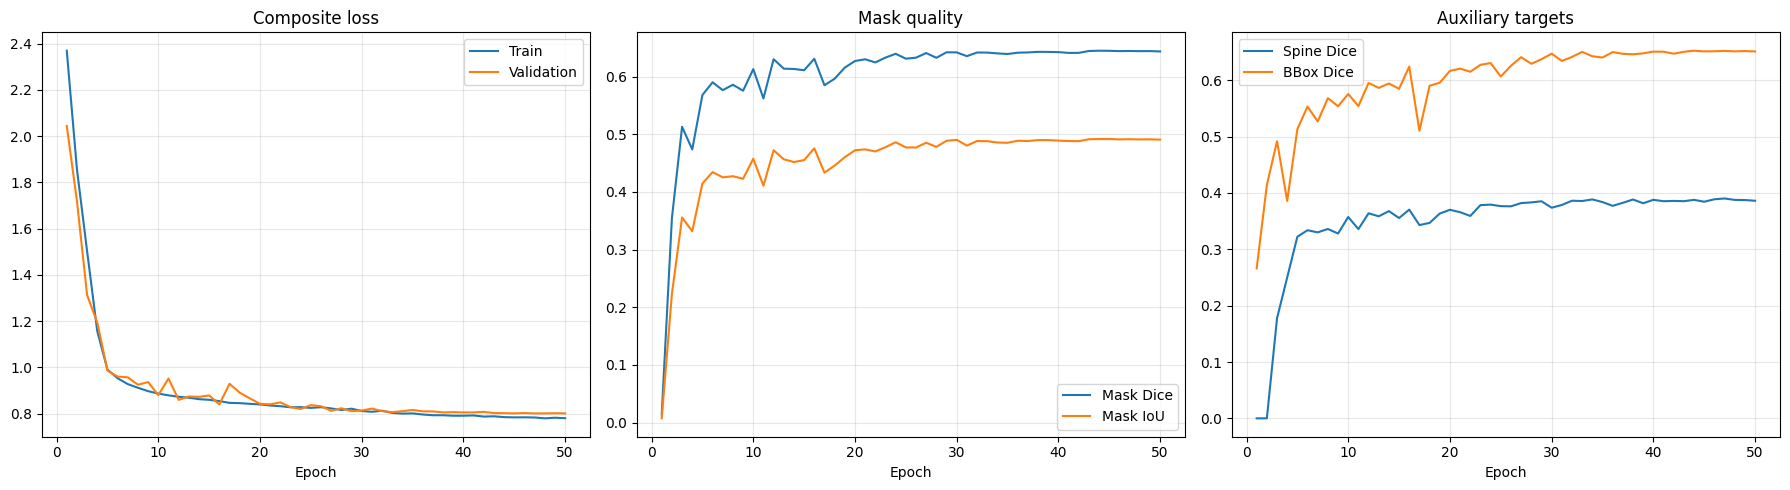

In [10]:
epochs = [r["epoch"] for r in history_v6]
tr_loss = [r["train"]["loss"] for r in history_v6]
va_loss = [r["val"]["loss"] for r in history_v6]
va_dice = [r["val"]["mask_dice"] for r in history_v6]
va_iou = [r["val"]["mask_iou"] for r in history_v6]
va_spine = [r["val"]["spine_dice"] for r in history_v6]
va_bbox = [r["val"]["bbox_dice"] for r in history_v6]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(epochs, tr_loss, label="Train")
axes[0].plot(epochs, va_loss, label="Validation")
axes[0].set_title("Composite loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(epochs, va_dice, label="Mask Dice")
axes[1].plot(epochs, va_iou, label="Mask IoU")
axes[1].set_title("Mask quality"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
axes[2].plot(epochs, va_spine, label="Spine Dice")
axes[2].plot(epochs, va_bbox, label="BBox Dice")
axes[2].set_title("Auxiliary targets"); axes[2].set_xlabel("Epoch"); axes[2].legend(); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 11. Controlled tuning sweep

In [11]:
tuning_trials_v6 = [
    {"trial_id": "T1-balanced", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 32, "epochs": 25},
    {"trial_id": "T2-spine-heavy", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.8, "w_bbox": 0.2, "base_channels": 32, "epochs": 25},
    {"trial_id": "T3-48ch", "lr": 8e-4, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 48, "epochs": 25},
    {"trial_id": "T4-box-guided", "lr": 1e-3, "w_mask": 1.0, "w_spine": 0.4, "w_bbox": 0.6, "base_channels": 32, "epochs": 25},
    {"trial_id": "T5-lr2e-3", "lr": 2e-3, "w_mask": 1.0, "w_spine": 0.5, "w_bbox": 0.3, "base_channels": 32, "epochs": 25},
]
print(pd.DataFrame(tuning_trials_v6))

         trial_id      lr  w_mask  w_spine  w_bbox  base_channels  epochs
0     T1-balanced  0.0010     1.0      0.5     0.3             32      25
1  T2-spine-heavy  0.0010     1.0      0.8     0.2             32      25
2         T3-48ch  0.0008     1.0      0.5     0.3             48      25
3   T4-box-guided  0.0010     1.0      0.4     0.6             32      25
4       T5-lr2e-3  0.0020     1.0      0.5     0.3             32      25


In [12]:
def run_trial(trial_cfg):
    global_vars = (config.MASK_LOSS_WEIGHT, config.SPINE_LOSS_WEIGHT, config.BBOX_LOSS_WEIGHT)
    config.MASK_LOSS_WEIGHT = trial_cfg["w_mask"]
    config.SPINE_LOSS_WEIGHT = trial_cfg["w_spine"]
    config.BBOX_LOSS_WEIGHT = trial_cfg["w_bbox"]

    model = EdgeAttFilamentUNet(
        in_channels=1,
        base_channels=trial_cfg["base_channels"],
        attn_heads=config.ATTN_HEADS,
        edge_scale=config.ATTN_EDGE_SCALE,
    ).to(config.DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=trial_cfg["lr"], weight_decay=config.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=trial_cfg["epochs"], eta_min=1e-6
    )
    scaler = make_scaler(config.DEVICE)

    best = {"dice": -1.0, "iou": 0.0, "epoch": 0}
    best_state = None
    curve = []

    print(f"\n=== {trial_cfg['trial_id']} ===")
    print(f"channels={trial_cfg['base_channels']} lr={trial_cfg['lr']} weights="
          f"{trial_cfg['w_mask']}:{trial_cfg['w_spine']}:{trial_cfg['w_bbox']}")

    for epoch in range(1, trial_cfg["epochs"] + 1):
        train_m = run_epoch(model, train_loader, optimizer, scaler, config.DEVICE)
        with torch.no_grad():
            val_m = run_epoch(model, val_loader, None, None, config.DEVICE)
        scheduler.step()

        curve.append({"epoch": epoch, "train": train_m, "val": val_m})
        if val_m["mask_dice"] > best["dice"]:
            best = {"dice": val_m["mask_dice"], "iou": val_m["mask_iou"], "epoch": epoch}
            best_state = deepcopy(model.state_dict())

        print(f"{epoch:02d}/{trial_cfg['epochs']} | val Dice={val_m['mask_dice']:.4f} | val IoU={val_m['mask_iou']:.4f}")

    result = {
        "Trial": trial_cfg["trial_id"],
        "Base Channels": trial_cfg["base_channels"],
        "LR": trial_cfg["lr"],
        "Weights": f"{trial_cfg['w_mask']}:{trial_cfg['w_spine']}:{trial_cfg['w_bbox']}",
        "Peak Mask Dice": best["dice"],
        "Peak Mask IoU": best["iou"],
        "Best Epoch": best["epoch"],
        "Parameters": count_parameters(model),
    }

    # Restore global configuration for the next trial caller.
    config.MASK_LOSS_WEIGHT, config.SPINE_LOSS_WEIGHT, config.BBOX_LOSS_WEIGHT = global_vars
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, best_state, curve


tuning_results_v6 = []
global_best = None
all_trial_curves = {}

for trial_cfg in tuning_trials_v6:
    result, state, curve = run_trial(trial_cfg)
    tuning_results_v6.append(result)
    all_trial_curves[trial_cfg["trial_id"]] = curve
    if global_best is None or result["Peak Mask Dice"] > global_best["result"]["Peak Mask Dice"]:
        global_best = {"result": result, "state": state, "trial": trial_cfg}

leaderboard_df = pd.DataFrame(tuning_results_v6).sort_values("Peak Mask Dice", ascending=False)
display(leaderboard_df)

if global_best is not None:
    cfg = global_best["trial"]
    champion_payload = {
        "epoch": int(global_best["result"]["Best Epoch"]),
        "model_state": global_best["state"],
        "model_config": {
            "in_channels": 1,
            "base_channels": cfg["base_channels"],
            "attn_heads": config.ATTN_HEADS,
            "edge_scale": config.ATTN_EDGE_SCALE,
        },
        "metrics": {
            "peak_mask_dice": global_best["result"]["Peak Mask Dice"],
            "peak_mask_iou": global_best["result"]["Peak Mask IoU"],
            "trial": cfg,
        },
    }
    torch.save(champion_payload, config.TUNED_MODEL_PATH)
    print(f"Champion saved: {config.TUNED_MODEL_PATH}")


=== T1-balanced ===
channels=32 lr=0.001 weights=1.0:0.5:0.3


C:\Users\atiks\AppData\Local\Temp\ipykernel_2692\2471882028.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  return torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


01/25 | val Dice=0.0284 | val IoU=0.0147
02/25 | val Dice=0.4085 | val IoU=0.2667
03/25 | val Dice=0.3254 | val IoU=0.2131
04/25 | val Dice=0.3504 | val IoU=0.2274
05/25 | val Dice=0.5832 | val IoU=0.4270
06/25 | val Dice=0.5777 | val IoU=0.4223
07/25 | val Dice=0.5523 | val IoU=0.3908
08/25 | val Dice=0.5912 | val IoU=0.4323
09/25 | val Dice=0.5271 | val IoU=0.3822
10/25 | val Dice=0.5753 | val IoU=0.4145
11/25 | val Dice=0.6022 | val IoU=0.4460
12/25 | val Dice=0.5941 | val IoU=0.4449
13/25 | val Dice=0.6122 | val IoU=0.4551
14/25 | val Dice=0.6076 | val IoU=0.4515
15/25 | val Dice=0.6315 | val IoU=0.4769
16/25 | val Dice=0.6353 | val IoU=0.4806
17/25 | val Dice=0.6314 | val IoU=0.4762
18/25 | val Dice=0.6345 | val IoU=0.4789
19/25 | val Dice=0.6391 | val IoU=0.4844
20/25 | val Dice=0.6347 | val IoU=0.4798
21/25 | val Dice=0.6380 | val IoU=0.4836
22/25 | val Dice=0.6389 | val IoU=0.4848
23/25 | val Dice=0.6388 | val IoU=0.4845
24/25 | val Dice=0.6382 | val IoU=0.4838
25/25 | val Dice

,Trial,Base Channels,LR,Weights,Peak Mask Dice,Peak Mask IoU,Best Epoch,Parameters
3,T4-box-guided,32,0.0010,1.0:0.4:0.6,0.641343,0.486964,25,9080931
2,T3-48ch,48,0.0008,1.0:0.5:0.3,0.639699,0.483056,24,20421267
0,T1-balanced,32,0.0010,1.0:0.5:0.3,0.639105,0.484412,19,9080931
1,T2-spine-heavy,32,0.0010,1.0:0.8:0.2,0.633540,0.476919,19,9080931
4,T5-lr2e-3,32,0.0020,1.0:0.5:0.3,0.414012,0.273125,1,9080931


Champion saved: v6_outputs\best_edgeatt_v6_tuned.pt


## 12. Instance post-processing

In [13]:
def resize_prob_map(prob, out_h, out_w):
    return cv2.resize(prob.astype(np.float32), (out_w, out_h), interpolation=cv2.INTER_LINEAR)


def extract_instances(mask_prob, spine_prob=None, bbox_prob=None):
    """Convert semantic outputs into individual instances.

    Default path: threshold + closing + connected components.
    Optional spine-watershed path: use the predicted spine as instance markers,
    then split connected mask regions with a distance-transform watershed.
    """
    threshold = config.PRED_THRESHOLD
    binary = (mask_prob >= threshold).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (config.MORPH_KERNEL_SIZE, config.MORPH_KERNEL_SIZE)
    )
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    if not config.USE_SPINE_WATERSHED or spine_prob is None:
        labeled = label(binary)
    else:
        spine_bin = (spine_prob >= config.SPINE_THRESHOLD).astype(np.uint8)
        spine_bin = cv2.morphologyEx(spine_bin, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

        # Compress the spine into seed regions. Erosion prevents a broad marker
        # from swallowing the entire connected component.
        spine_core = cv2.erode(spine_bin, np.ones((3, 3), np.uint8), iterations=1)
        marker_labels = label(spine_core)

        # If spine markers are absent, fall back to connected components.
        if marker_labels.max() == 0:
            labeled = label(binary)
        else:
            distance = ndi.distance_transform_edt(binary)
            labeled = watershed(-distance, markers=marker_labels, mask=binary)

    regions = regionprops(labeled)
    regions = [r for r in regions if r.area >= config.MIN_FILAMENT_AREA]
    regions = sorted(regions, key=lambda r: r.area, reverse=True)[:config.MAX_FILAMENTS_PER_IMG]

    instances = []
    for r in regions:
        inst = (labeled == r.label).astype(np.uint8)
        instances.append(inst)

    if not instances:
        fallback = (mask_prob >= 0.35).astype(np.uint8)
        fallback_labels = label(fallback)
        fb_regions = [r for r in regionprops(fallback_labels) if r.area >= max(50, config.MIN_FILAMENT_AREA // 2)]
        if fb_regions:
            best_r = max(fb_regions, key=lambda r: r.area)
            instances = [(fallback_labels == best_r.label).astype(np.uint8)]

    if not instances:
        # Absolute last resort (FIXED): guarantee at least one instance so
        # no validation or test image is ever silently skipped. Uses the
        # single highest-probability pixel in the mask prediction itself --
        # this function only has access to the probability maps, not the
        # raw image, so it cannot fall back to a raw-intensity heuristic.
        ys, xs = np.unravel_index(np.argmax(mask_prob), mask_prob.shape)
        forced = np.zeros_like(mask_prob, dtype=np.uint8)
        y0, y1 = max(0, ys - 2), min(mask_prob.shape[0], ys + 3)
        x0, x1 = max(0, xs - 2), min(mask_prob.shape[1], xs + 3)
        forced[y0:y1, x0:x1] = 1
        instances = [forced]

    return instances


def mask_to_coco_rle(binary_mask):
    rle = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    return rle["counts"].decode("utf-8") if isinstance(rle["counts"], bytes) else rle["counts"]

## 13. Visualize validation predictions

Baseline peak Dice: 0.6448941241354632  |  Tuned peak Dice: 0.6413431414485683
Selected checkpoint: v6_outputs\best_edgeatt_v6_50ep.pt (peak Dice: 0.6449)
Loaded: v6_outputs\best_edgeatt_v6_50ep.pt
Checkpoint metrics: {'loss': 0.8015884781730246, 'mask_dice': 0.6448941241354632, 'mask_iou': 0.4916925994602181, 'spine_dice': 0.3878394869657663, 'bbox_dice': 0.6525639284997297}


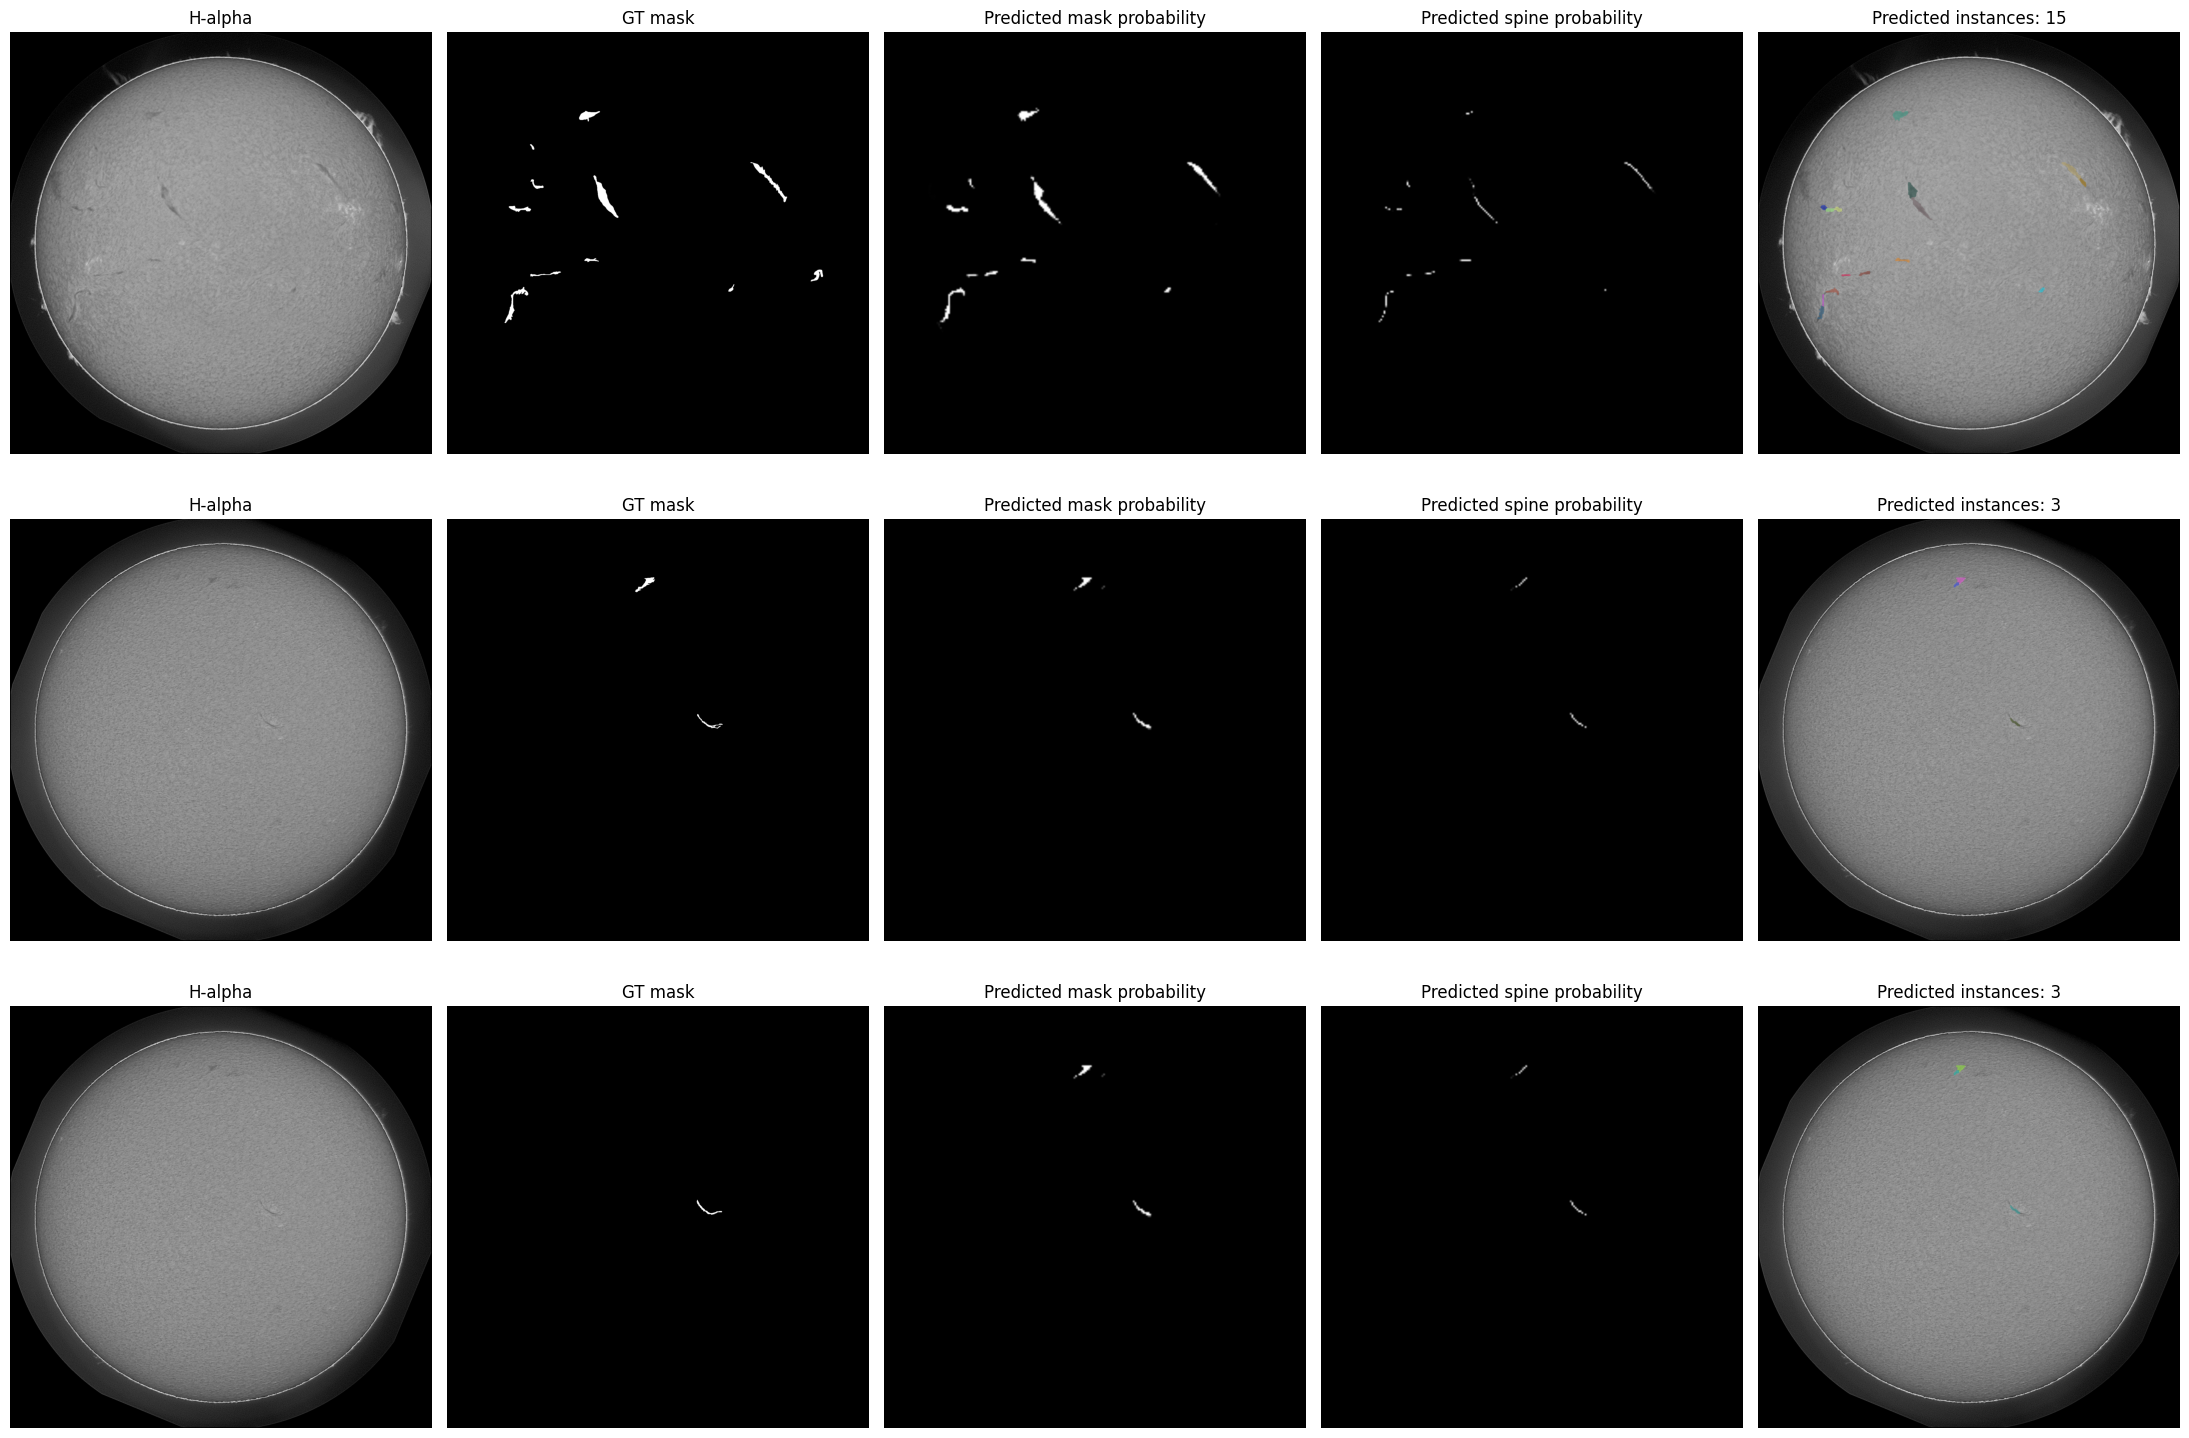

In [15]:
# FIXED: actually compare baseline vs tuned peak Dice rather than
# unconditionally preferring the tuned checkpoint whenever it exists --
# the baseline trains for the full 50-epoch schedule while each tuning
# trial is capped at 25 epochs, so the baseline can legitimately win.
def _checkpoint_score(path):
    if not path.exists():
        return None
    payload = torch.load(path, map_location=config.DEVICE)
    metrics = payload.get("metrics", {})
    return metrics.get("peak_mask_dice", metrics.get("mask_dice", -1.0))

candidates = []
baseline_score = _checkpoint_score(config.BASELINE_MODEL_PATH)
if baseline_score is not None:
    candidates.append((config.BASELINE_MODEL_PATH, baseline_score))
tuned_score = _checkpoint_score(config.TUNED_MODEL_PATH)
if tuned_score is not None:
    candidates.append((config.TUNED_MODEL_PATH, tuned_score))

if not candidates:
    raise FileNotFoundError("No checkpoint found at BASELINE_MODEL_PATH or TUNED_MODEL_PATH.")

checkpoint_for_eval, best_score = max(candidates, key=lambda x: x[1])
print(f"Baseline peak Dice: {baseline_score}  |  Tuned peak Dice: {tuned_score}")
print(f"Selected checkpoint: {checkpoint_for_eval} (peak Dice: {best_score:.4f})")

final_model, checkpoint_meta = load_checkpoint(checkpoint_for_eval, config.DEVICE)
final_model.eval()
print("Loaded:", checkpoint_for_eval)
print("Checkpoint metrics:", checkpoint_meta.get("metrics", {}))

viz_samples = val_samples[:3]
fig, axes = plt.subplots(len(viz_samples), 5, figsize=(22, 5 * len(viz_samples)), squeeze=False)

for row, sample in enumerate(viz_samples):
    img = np.asarray(Image.open(sample["file_path"]).convert("L"))
    gt_mask, gt_spine, gt_bbox = rasterize_union_targets(sample, sample["width"], sample["height"])
    small = Image.fromarray(img).resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.Resampling.BILINEAR)
    inp = torch.from_numpy(np.asarray(small, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)

    with torch.no_grad():
        with autocast_context(config.DEVICE):
            out = final_model(inp)
    mask_prob = resize_prob_map(torch.sigmoid(out["mask"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    spine_prob = resize_prob_map(torch.sigmoid(out["spine"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    instances = extract_instances(mask_prob, spine_prob)

    ax = axes[row]
    ax[0].imshow(img, cmap="gray"); ax[0].set_title("H-alpha"); ax[0].axis("off")
    ax[1].imshow(gt_mask, cmap="gray"); ax[1].set_title("GT mask"); ax[1].axis("off")
    ax[2].imshow(mask_prob, cmap="gray", vmin=0, vmax=1); ax[2].set_title("Predicted mask probability"); ax[2].axis("off")
    ax[3].imshow(spine_prob, cmap="gray", vmin=0, vmax=1); ax[3].set_title("Predicted spine probability"); ax[3].axis("off")
    ax[4].imshow(img, cmap="gray")
    
    # Draw instances with deterministic random hues.
    # FIX: Generate an integer seed safely from the string image_id
    seed = sum(ord(c) for c in str(sample["image_id"])) + 17
    rng = np.random.default_rng(seed)
    
    for inst in instances:
        col = rng.random(3)
        overlay = np.zeros((*inst.shape, 4), dtype=float)
        overlay[..., :3] = col
        overlay[..., 3] = inst * 0.55
        ax[4].imshow(overlay)
    ax[4].set_title(f"Predicted instances: {len(instances)}"); ax[4].axis("off")

plt.tight_layout(); plt.show()


## 14. One-to-one local PQ evaluator

Baseline peak Dice: 0.6448941241354632  |  Tuned peak Dice: 0.6413431414485683
Selected checkpoint: v6_outputs\best_edgeatt_v6_50ep.pt (peak Dice: 0.6449)
Loaded: v6_outputs\best_edgeatt_v6_50ep.pt
Checkpoint metrics: {'loss': 0.8015884781730246, 'mask_dice': 0.6448941241354632, 'mask_iou': 0.4916925994602181, 'spine_dice': 0.3878394869657663, 'bbox_dice': 0.6525639284997297}


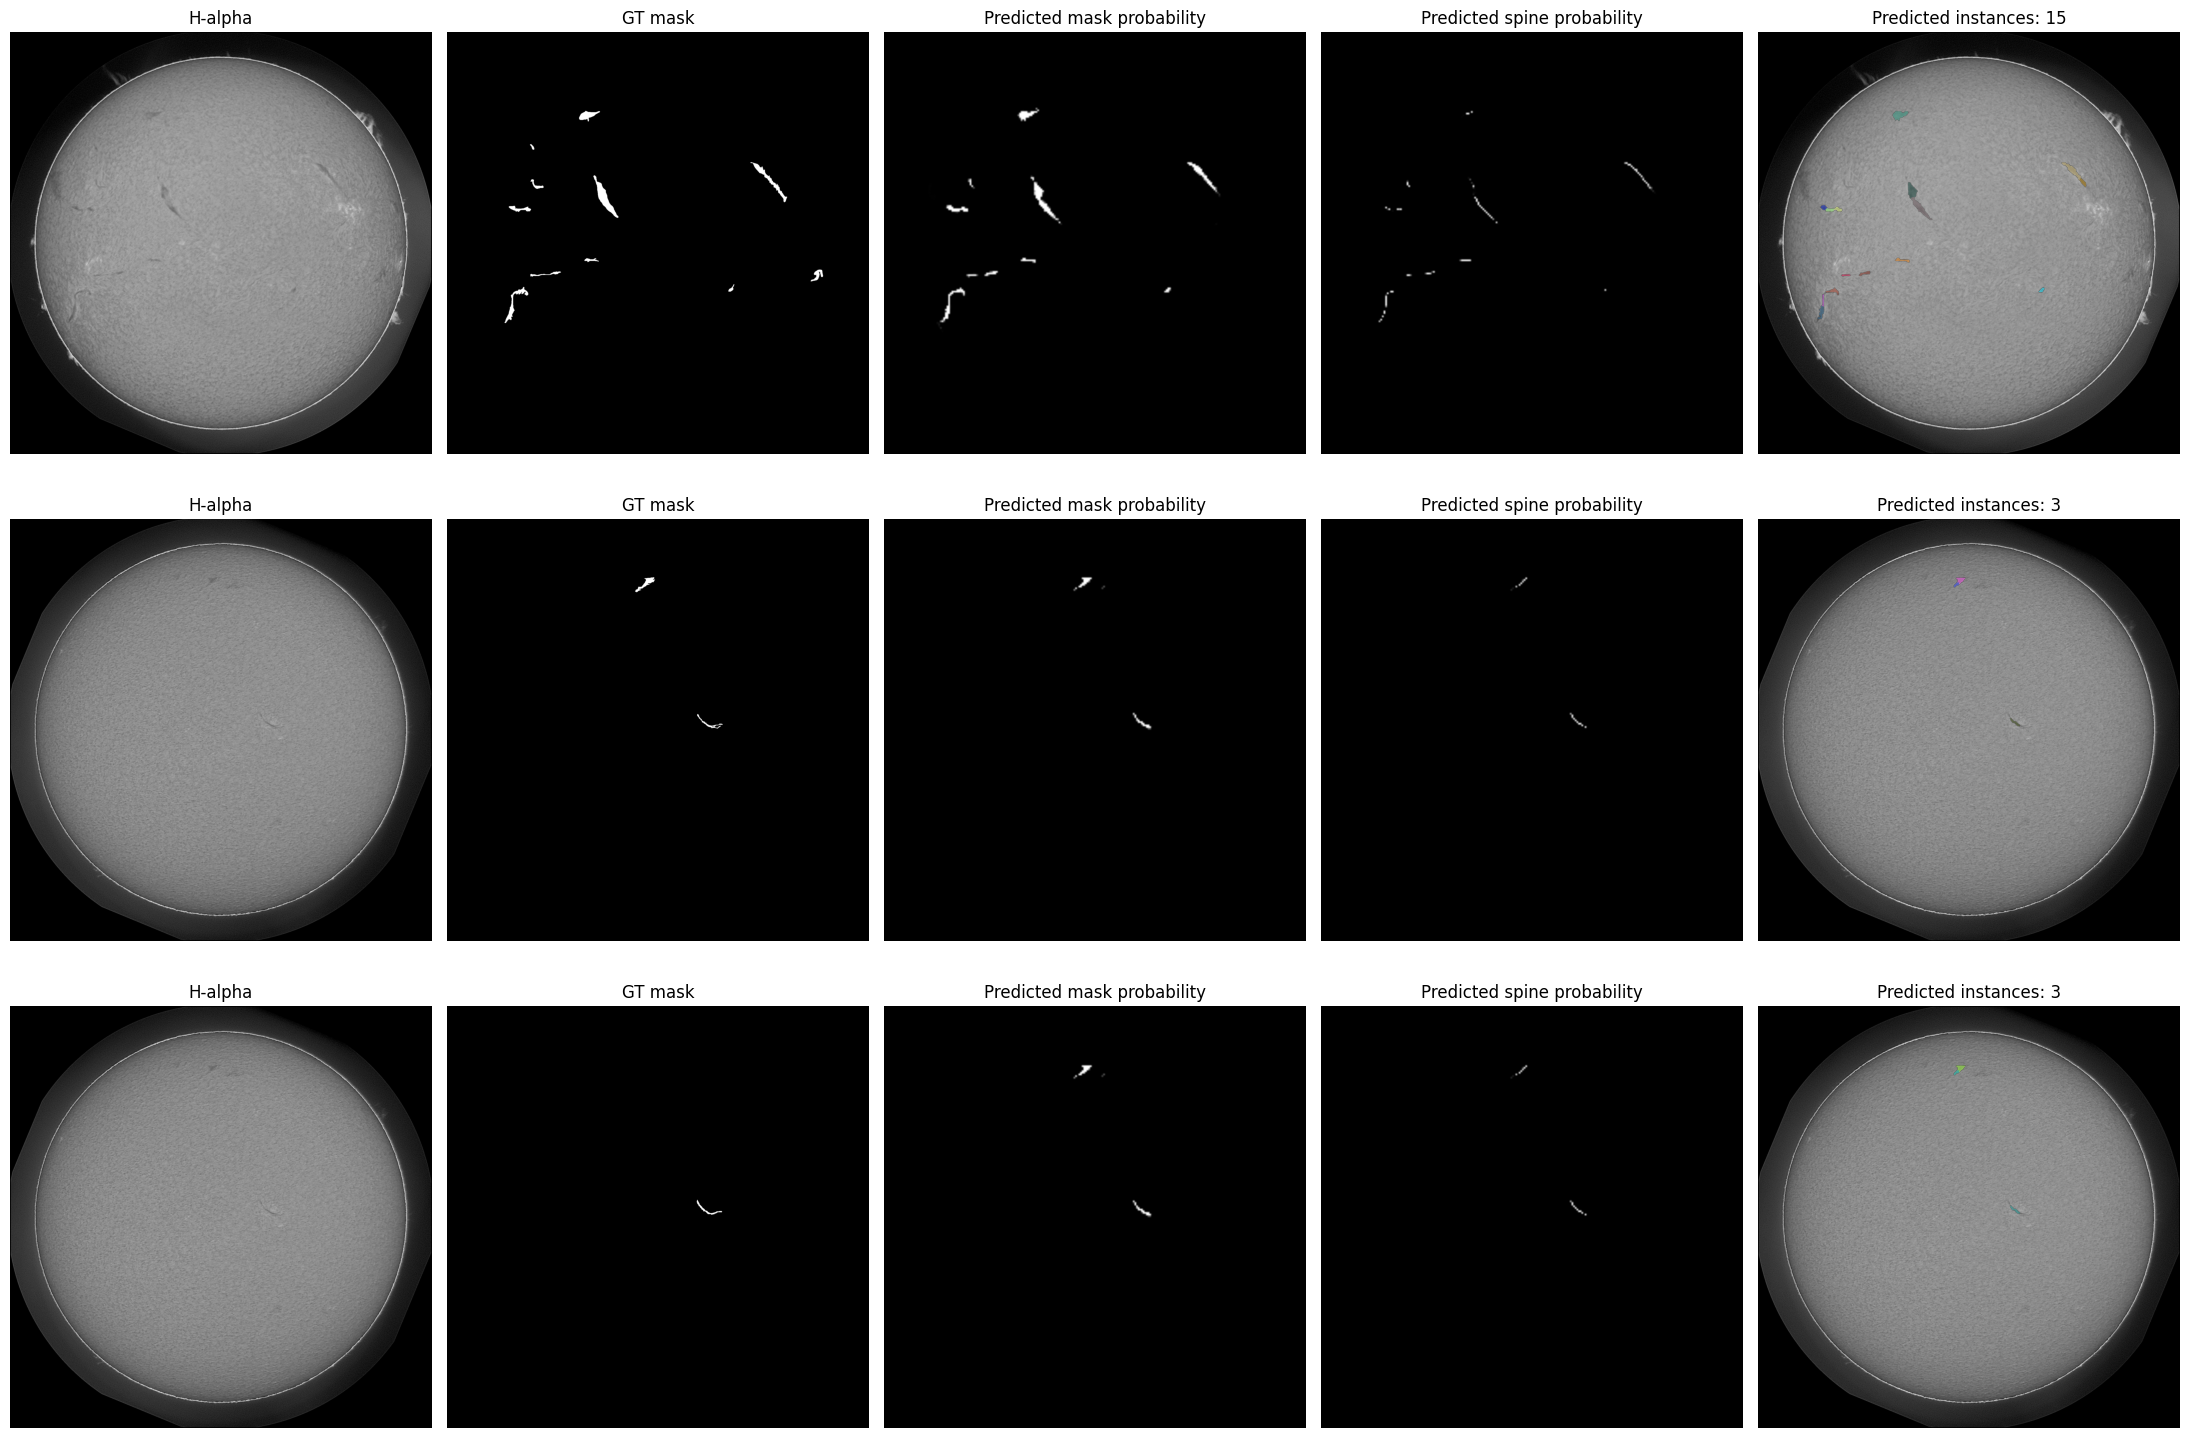

In [18]:
# FIXED: actually compare baseline vs tuned peak Dice rather than
# unconditionally preferring the tuned checkpoint whenever it exists --
# the baseline trains for the full 50-epoch schedule while each tuning
# trial is capped at 25 epochs, so the baseline can legitimately win.
def _checkpoint_score(path):
    if not path.exists():
        return None
    payload = torch.load(path, map_location=config.DEVICE)
    metrics = payload.get("metrics", {})
    return metrics.get("peak_mask_dice", metrics.get("mask_dice", -1.0))

candidates = []
baseline_score = _checkpoint_score(config.BASELINE_MODEL_PATH)
if baseline_score is not None:
    candidates.append((config.BASELINE_MODEL_PATH, baseline_score))
tuned_score = _checkpoint_score(config.TUNED_MODEL_PATH)
if tuned_score is not None:
    candidates.append((config.TUNED_MODEL_PATH, tuned_score))

if not candidates:
    raise FileNotFoundError("No checkpoint found at BASELINE_MODEL_PATH or TUNED_MODEL_PATH.")

checkpoint_for_eval, best_score = max(candidates, key=lambda x: x[1])
print(f"Baseline peak Dice: {baseline_score}  |  Tuned peak Dice: {tuned_score}")
print(f"Selected checkpoint: {checkpoint_for_eval} (peak Dice: {best_score:.4f})")

final_model, checkpoint_meta = load_checkpoint(checkpoint_for_eval, config.DEVICE)
final_model.eval()
print("Loaded:", checkpoint_for_eval)
print("Checkpoint metrics:", checkpoint_meta.get("metrics", {}))

viz_samples = val_samples[:3]
fig, axes = plt.subplots(len(viz_samples), 5, figsize=(22, 5 * len(viz_samples)), squeeze=False)

for row, sample in enumerate(viz_samples):
    img = np.asarray(Image.open(sample["file_path"]).convert("L"))
    gt_mask, gt_spine, gt_bbox = rasterize_union_targets(sample, sample["width"], sample["height"])
    small = Image.fromarray(img).resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.Resampling.BILINEAR)
    inp = torch.from_numpy(np.asarray(small, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)

    with torch.no_grad():
        with autocast_context(config.DEVICE):
            out = final_model(inp)
    mask_prob = resize_prob_map(torch.sigmoid(out["mask"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    spine_prob = resize_prob_map(torch.sigmoid(out["spine"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    instances = extract_instances(mask_prob, spine_prob)

    ax = axes[row]
    ax[0].imshow(img, cmap="gray"); ax[0].set_title("H-alpha"); ax[0].axis("off")
    ax[1].imshow(gt_mask, cmap="gray"); ax[1].set_title("GT mask"); ax[1].axis("off")
    ax[2].imshow(mask_prob, cmap="gray", vmin=0, vmax=1); ax[2].set_title("Predicted mask probability"); ax[2].axis("off")
    ax[3].imshow(spine_prob, cmap="gray", vmin=0, vmax=1); ax[3].set_title("Predicted spine probability"); ax[3].axis("off")
    ax[4].imshow(img, cmap="gray")
    
    # Draw instances with deterministic random hues.
    seed = sum(ord(c) for c in str(sample["image_id"])) + 17
    rng = np.random.default_rng(seed)
    
    # FAST RENDERING FIX: Pre-allocate a single overlay for all instances
    overlay = np.zeros((*img.shape, 4), dtype=float)
    
    for inst in instances:
        col = rng.random(3)
        # Apply color only to the pixels where this instance exists
        mask_idx = (inst > 0)
        overlay[mask_idx, :3] = col
        overlay[mask_idx, 3] = 0.55
        
    # Call imshow exactly ONCE per image instead of repeatedly inside the loop
    ax[4].imshow(overlay)
    ax[4].set_title(f"Predicted instances: {len(instances)}"); ax[4].axis("off")

plt.tight_layout(); plt.show()


## 15. Error analysis: fragmentation vs merging

In [19]:
# The counts below use an overlap diagnostic of IoU > 0.1, not the official match threshold.
print("One-to-many (GT filament overlapping multiple predictions):")
print(pd.Series(pq_results_v6["one_to_many_overlap_counts"]).value_counts().sort_index())
print("\nMany-to-one (prediction overlapping multiple GT filaments):")
print(pd.Series(pq_results_v6["many_to_one_overlap_counts"]).value_counts().sort_index())

if pq_results_v6["matched_ious"]:
    plt.figure(figsize=(8, 4))
    plt.hist(pq_results_v6["matched_ious"], bins=20)
    plt.axvline(config.MATCH_IOU_THRESHOLD, linestyle="--", label="match threshold")
    plt.xlabel("Matched IoU"); plt.ylabel("Count"); plt.title("Matched instance IoUs"); plt.legend(); plt.grid(alpha=.3)
    plt.show()

One-to-many (GT filament overlapping multiple predictions):


NameError: name 'pq_results_v6' is not defined

## 16. Generate competition submission

In [24]:
import csv

def predict_test_submission(model):
    test_files = sorted(
        [p for p in config.TEST_IMG_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}],
        key=lambda p: p.name
    )
    rows = []
    model.eval()

    print(f"Test images: {len(test_files)}")
    for path in tqdm(test_files, desc="Test inference"):
        img = Image.open(path).convert("L")
        w, h = img.size
        arr = np.asarray(img, dtype=np.float32) / 255.0
        resized = cv2.resize(arr, (config.IMAGE_SIZE, config.IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        inp = torch.from_numpy(resized).unsqueeze(0).unsqueeze(0).to(config.DEVICE)

        with torch.no_grad():
            with autocast_context(config.DEVICE):
                out = model(inp)

        mask_prob = resize_prob_map(torch.sigmoid(out["mask"])[0, 0].float().cpu().numpy(), h, w)
        spine_prob = resize_prob_map(torch.sigmoid(out["spine"])[0, 0].float().cpu().numpy(), h, w)
        bbox_prob = resize_prob_map(torch.sigmoid(out["bbox"])[0, 0].float().cpu().numpy(), h, w)
        
        instances = extract_instances(mask_prob, spine_prob, bbox_prob)

        stem = path.stem
        
        if len(instances) > 0:
            for idx, inst in enumerate(instances, start=1):
                # 1. Guarantee the instance mask is exactly 2048x2048 as expected by Kaggle
                if inst.shape != (2048, 2048):
                    inst_2048 = cv2.resize(
                        inst.astype(np.uint8), 
                        (2048, 2048), 
                        interpolation=cv2.INTER_NEAREST
                    )
                else:
                    inst_2048 = inst
                
                rows.append({
                    "filament_id": f"{stem}_{idx}",
                    "segmentation_rle": mask_to_coco_rle(inst_2048),
                })
        else:
            # 2. If 0 filaments are found, output an empty mask row for Kaggle completeness
            rows.append({
                "filament_id": f"{stem}_1",
                "segmentation_rle": ""
            })

    submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
    
    # 3. Save without quotes
    submission.to_csv(config.SUBMISSION_PATH, index=False, quoting=csv.QUOTE_NONE)    
    print(f"Saved {len(submission)} instances to {config.SUBMISSION_PATH}")
    print(submission.head())
    return submission

submission_v6 = predict_test_submission(final_model)


Test images: 180


Test inference: 100%|██████████| 180/180 [11:04<00:00,  3.69s/it]

Saved 2146 instances to v6_outputs\submission_v6_1.csv
          filament_id                                   segmentation_rle
0  20110120105534Ch_1  [gPS22mo12N2N2O1O001ePNGmn1;PQNGon1g0N1O1O1O1O...
1  20110120105534Ch_2  Vi\R21no16YOc0N5K1O010O00000GHa00000010O01O2N3...
2  20110120105534Ch_3  PaPj26io13O1N1O00O0OLIcPN5\o1441J52O001O1O1O2N...
3  20110120105534Ch_4  l_Pi29go11O00010O002N2N5MOOO2O01gPNGjn18VQNHkn...
4  20110130110334Ch_1  aanf22fo1:M2O1RQNCWn1>gQNDXn1<gQNEYn1<fQNDZn1=...


Evaluating 169 validation samples to find the worst errors...


Scoring: 100%|██████████| 169/169 [00:39<00:00,  4.25it/s]


Visualizing the 3 worst performing images (Dice scores: ['0.0000', '0.0000', '0.0000'])


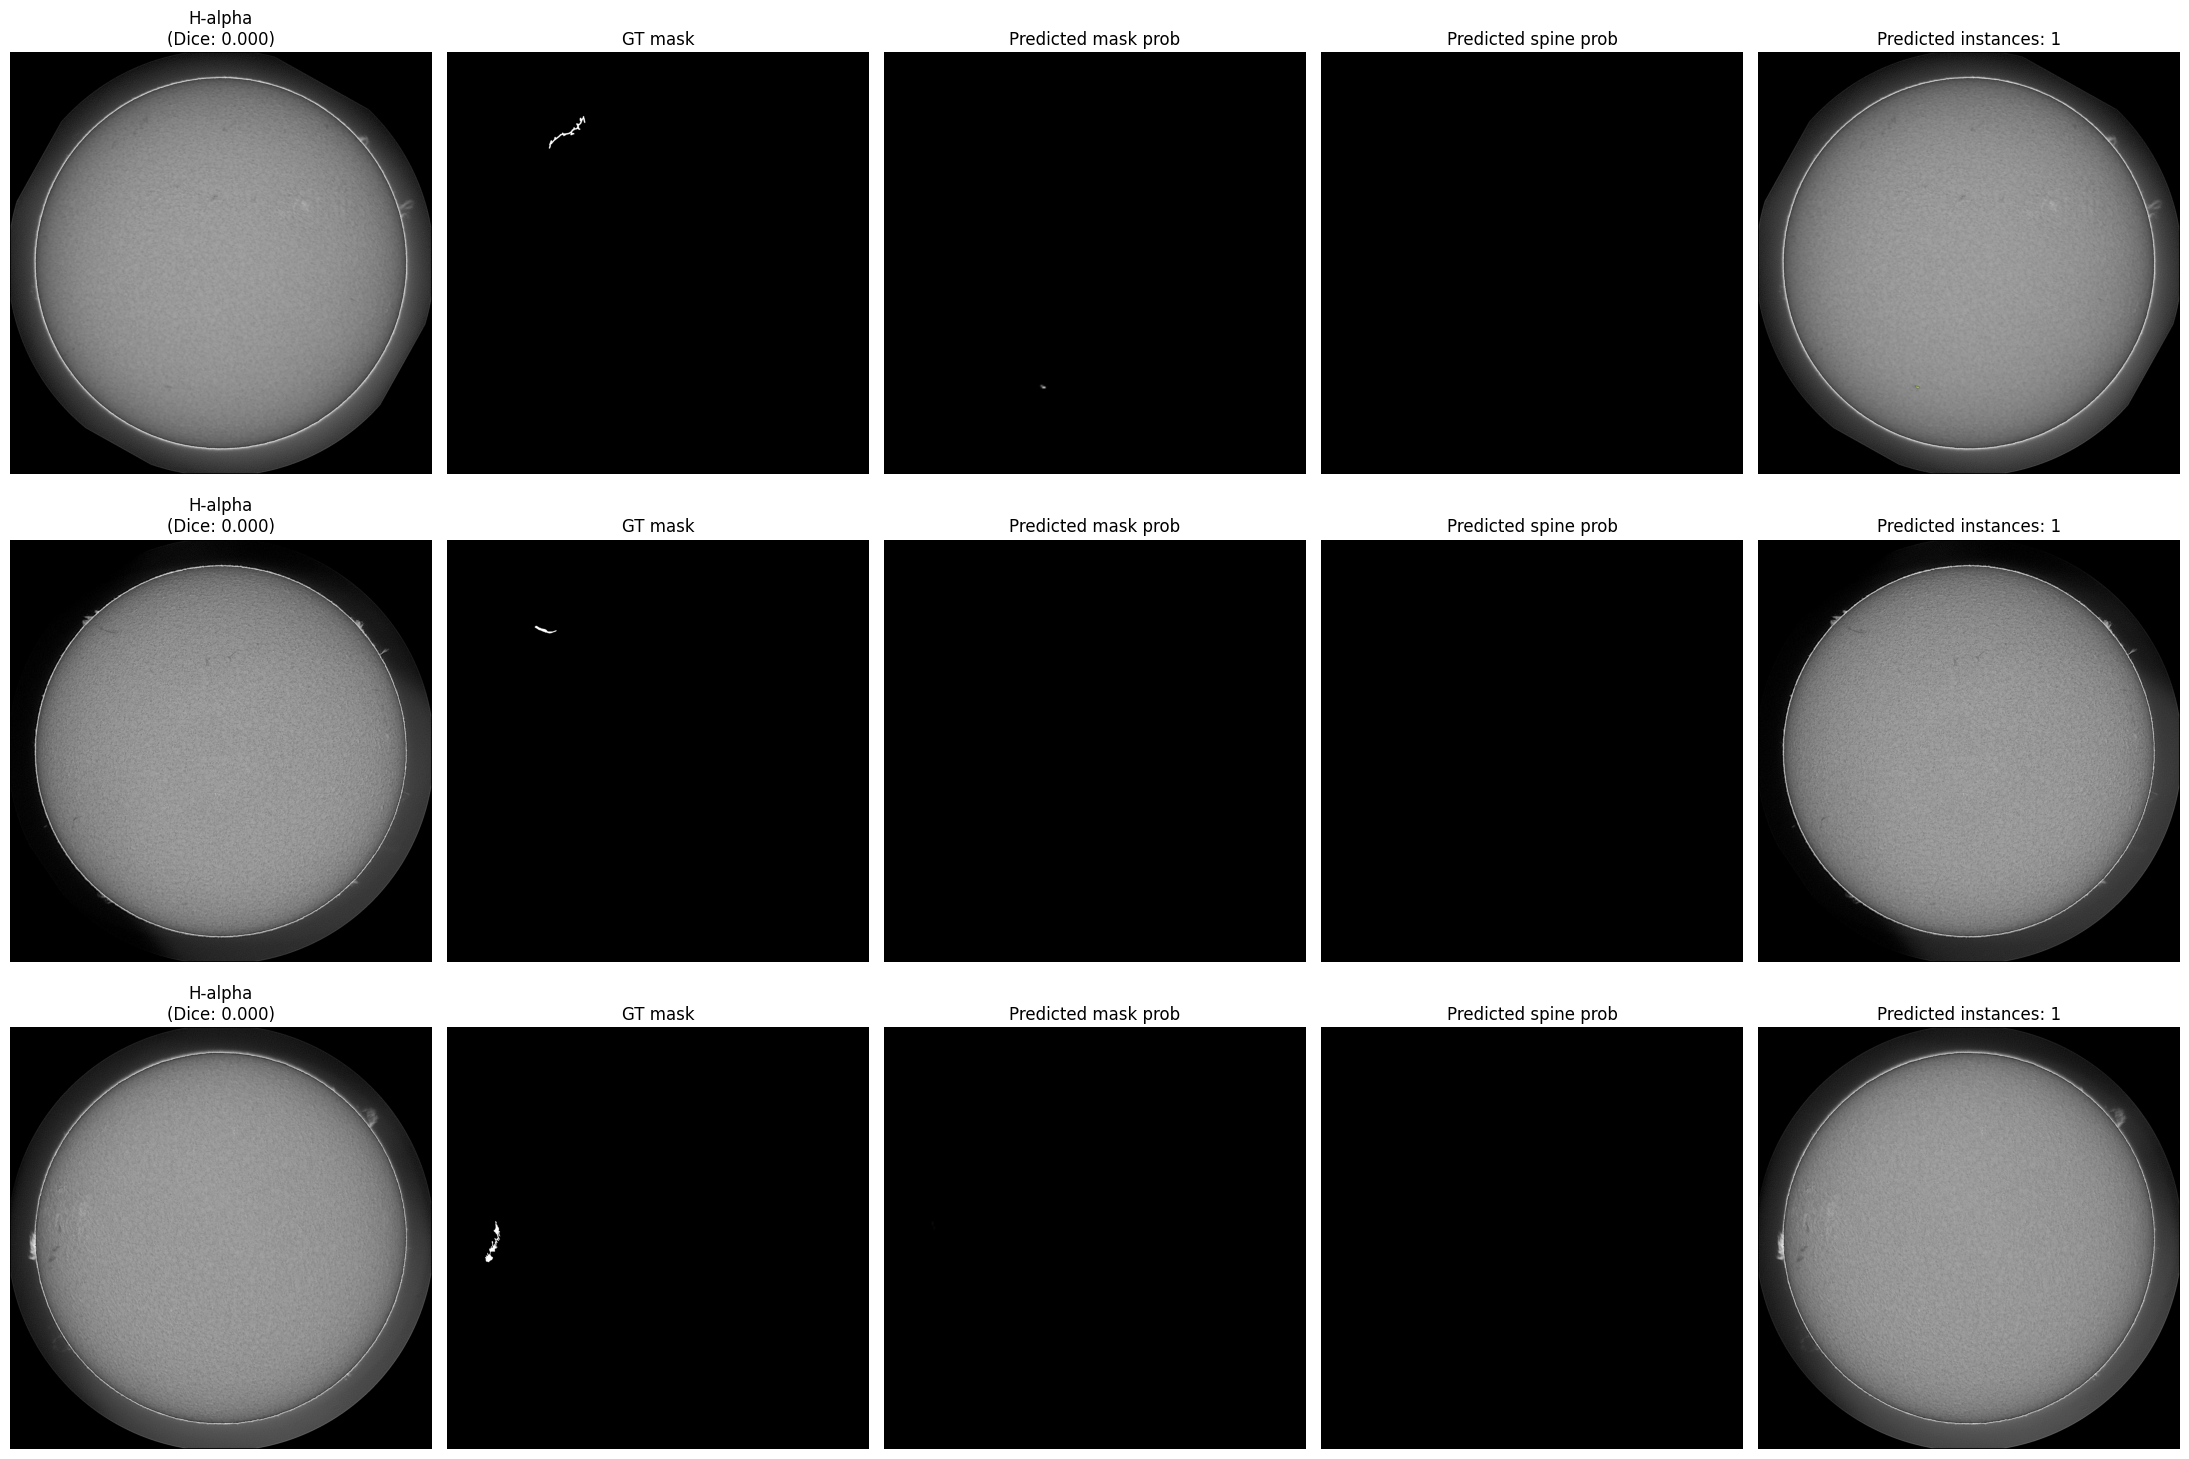

In [23]:
# 1. Evaluate all validation samples to find the worst-performing ones
sample_scores = []
final_model.eval()

print(f"Evaluating {len(val_samples)} validation samples to find the worst errors...")
for sample in tqdm(val_samples, desc="Scoring"):
    img = np.asarray(Image.open(sample["file_path"]).convert("L"))
    gt_mask, gt_spine, gt_bbox = rasterize_union_targets(sample, sample["width"], sample["height"])
    
    small = Image.fromarray(img).resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.Resampling.BILINEAR)
    inp = torch.from_numpy(np.asarray(small, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)

    with torch.no_grad():
        with autocast_context(config.DEVICE):
            out = final_model(inp)
            
    # Resize prediction back to original size for a fair comparison against GT
    mask_prob = resize_prob_map(torch.sigmoid(out["mask"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    
    # Calculate simple Dice score on the binary arrays
    pred_bin = mask_prob >= config.PRED_THRESHOLD
    gt_bin = gt_mask > 0
    
    intersection = np.logical_and(pred_bin, gt_bin).sum()
    dice = (2.0 * intersection) / (pred_bin.sum() + gt_bin.sum() + 1e-8)
    
    sample_scores.append((dice, sample))

# 2. Sort by score ascending (lowest Dice score = worst prediction)
sample_scores.sort(key=lambda x: x[0])

# 3. Pick the 3 worst samples
worst_3_samples = [s[1] for s in sample_scores[:3]]
worst_3_scores = [s[0] for s in sample_scores[:3]]

print(f"Visualizing the 3 worst performing images (Dice scores: {[f'{s:.4f}' for s in worst_3_scores]})")

# 4. Visualize them using the fast overlay code
fig, axes = plt.subplots(len(worst_3_samples), 5, figsize=(22, 5 * len(worst_3_samples)), squeeze=False)

for row, sample in enumerate(worst_3_samples):
    img = np.asarray(Image.open(sample["file_path"]).convert("L"))
    gt_mask, gt_spine, gt_bbox = rasterize_union_targets(sample, sample["width"], sample["height"])
    
    small = Image.fromarray(img).resize((config.IMAGE_SIZE, config.IMAGE_SIZE), Image.Resampling.BILINEAR)
    inp = torch.from_numpy(np.asarray(small, dtype=np.float32) / 255.0).unsqueeze(0).unsqueeze(0).to(config.DEVICE)

    with torch.no_grad():
        with autocast_context(config.DEVICE):
            out = final_model(inp)
            
    mask_prob = resize_prob_map(torch.sigmoid(out["mask"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    spine_prob = resize_prob_map(torch.sigmoid(out["spine"])[0, 0].float().cpu().numpy(), img.shape[0], img.shape[1])
    instances = extract_instances(mask_prob, spine_prob)

    ax = axes[row]
    # Show the Dice score in the title of the first image so you know how bad it was
    ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"H-alpha\n(Dice: {worst_3_scores[row]:.3f})"); ax[0].axis("off")
    ax[1].imshow(gt_mask, cmap="gray"); ax[1].set_title("GT mask"); ax[1].axis("off")
    ax[2].imshow(mask_prob, cmap="gray", vmin=0, vmax=1); ax[2].set_title("Predicted mask prob"); ax[2].axis("off")
    ax[3].imshow(spine_prob, cmap="gray", vmin=0, vmax=1); ax[3].set_title("Predicted spine prob"); ax[3].axis("off")
    ax[4].imshow(img, cmap="gray")
    
    # Fast rendering overlay
    seed = sum(ord(c) for c in str(sample["image_id"])) + 17
    rng = np.random.default_rng(seed)
    overlay = np.zeros((*img.shape, 4), dtype=float)
    
    for inst in instances:
        col = rng.random(3)
        mask_idx = (inst > 0)
        overlay[mask_idx, :3] = col
        overlay[mask_idx, 3] = 0.55
        
    ax[4].imshow(overlay)
    ax[4].set_title(f"Predicted instances: {len(instances)}"); ax[4].axis("off")

plt.tight_layout(); plt.show()


## 17. Save experiment metadata

In [21]:
experiment_summary = {
    "seed": SEED,
    "device": str(config.DEVICE),
    "train_images": len(train_samples),
    "val_images": len(val_samples),
    "image_size": config.IMAGE_SIZE,
    "batch_size": config.BATCH_SIZE,
    "baseline_epochs": config.NUM_EPOCHS,
    "base_channels": config.BASE_CHANNELS,
    "attention_heads": config.ATTN_HEADS,
    "loss_weights": {
        "mask": config.MASK_LOSS_WEIGHT,
        "spine": config.SPINE_LOSS_WEIGHT,
        "bbox": config.BBOX_LOSS_WEIGHT,
    },
    "postprocessing": {
        "threshold": config.PRED_THRESHOLD,
        "spine_threshold": config.SPINE_THRESHOLD,
        "min_area": config.MIN_FILAMENT_AREA,
        "max_instances": config.MAX_FILAMENTS_PER_IMG,
        "watershed": config.USE_SPINE_WATERSHED,
    },
    "validation_pq": {k: pq_results_v6[k] for k in ["PQ", "SQ", "RQ", "TP", "FP", "FN", "mean_matched_iou"]},
    "submission_instances": len(submission_v6),
}

with open(config.HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump({"history": history_v6, "experiment": experiment_summary}, f, indent=2, default=float)

print(json.dumps(experiment_summary, indent=2, default=float))
print(f"\nArtifacts:\n- {config.BASELINE_MODEL_PATH}\n- {config.TUNED_MODEL_PATH}\n- {config.SUBMISSION_PATH}\n- {config.HISTORY_PATH}")

NameError: name 'pq_results_v6' is not defined